# Caffeine, Work, Sleep, and Well-Being: Simplified Analysis

**Goal:** build one clean participant-level dataset, compare caffeine consumption by age and sex, examine pairwise caffeine/outcome relationships, and prepare separate machine-learning models for sleep, work hours, focus difficulty, and worry/anxiety frequency.

This notebook keeps the core data-loading, cleaning, demographic comparisons, pairwise relationship checks, and machine-learning steps. It avoids repeated plots, duplicate statistical models, food-record deep dives, and extensive sensitivity analyses.

**Important limitations**
- Caffeine is based on NHANES Day 1 dietary recall, not a person's usual long-term intake.
- The worry/anxiety questions are indicators of worry/anxiety frequency, not a validated stress scale.
- This is observational data, so results show associations/predictions, not cause and effect.
- The models below are exploratory and do not account for the full NHANES complex survey design.

## 1. Import libraries and load the required NHANES files

Only the files needed for the four research outcomes and basic demographic controls are loaded. Update `data_path` if your project folder is in a different location.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

data_path = Path(r"C:\Users\Savio\OneDrive\Desktop\DS2\Project 3")

dietary_df = pd.read_sas(data_path / "DR1IFF_J.xpt", format = "xport")
occupation_df = pd.read_sas(data_path / "OCQ_J.xpt", format = "xport")
sleep_df = pd.read_sas(data_path / "SLQ_J.xpt", format = "xport")
mental_df = pd.read_sas(data_path / "DPQ_J.xpt", format = "xport")
worry_df = pd.read_sas(data_path / "DLQ_J.xpt", format = "xport")
demographics_df = pd.read_sas(data_path / "DEMO_J.xpt", format = "xport")

## 2. Calculate each participant's Day 1 caffeine intake

Sum caffeine across the participant's reported food and beverage items. This should match NHANES's official Day 1 total (`DR1TCAFF`) when checked against the total-intake file.

In [3]:
caffeine_total = (dietary_df.groupby("SEQN")["DR1ICAFF"].sum(min_count = 1).reset_index().rename(columns = {"DR1ICAFF": "Caffeine_mg"}))

# Optional verification against NHANES's official total.
dietary_totals = pd.read_sas(data_path / "DR1TOT_J.xpt", format="xport")
caffeine_check = caffeine_total.merge(dietary_totals[["SEQN", "DR1TCAFF"]], on = "SEQN", how = "inner")
caffeine_check["Difference"] = caffeine_check["Caffeine_mg"] - caffeine_check["DR1TCAFF"]

print("Participants checked:", len(caffeine_check))
print("Largest absolute difference (mg):", caffeine_check["Difference"].abs().max())

Participants checked: 7640
Largest absolute difference (mg): 1.8351858179575695e-77


## 3. Select, clean, and combine the variables

Special missing-value codes are changed to missing values. The questionnaire responses are kept as ordered numeric scores for machine learning.

In [4]:
occupation = occupation_df[["SEQN", "OCQ180"]].copy()
sleep = sleep_df[["SEQN", "SLD012"]].copy()
mental = mental_df[["SEQN", "DPQ070"]].copy()
worry = worry_df[["SEQN", "DLQ100"]].copy()
demographics = demographics_df[["SEQN", "RIDAGEYR", "RIAGENDR"]].copy()

In [5]:
# Convert selected fields to numeric.
for frame in [occupation, sleep, mental, worry, demographics]:
    for column in frame.columns:
        if column != "SEQN":
            frame[column] = pd.to_numeric(frame[column], errors = "coerce")

# Work hours: 77777 and 99999 are nonresponse codes.
occupation["OCQ180"] = occupation["OCQ180"].replace([77777, 99999], np.nan)

# Focus difficulty: 0-3 are valid responses; 7 and 9 are nonresponse codes.
mental["DPQ070"] = mental["DPQ070"].replace([7, 9], np.nan)
mental.loc[mental["DPQ070"].abs() < 1e-50, "DPQ070"] = 0

# Worry/anxiety frequency: 1=Daily, 2=Weekly, 3=Monthly,
# 4=A few times a year, 5=Never. 7 and 9 are nonresponse codes.
worry["DLQ100"] = worry["DLQ100"].replace([7, 9], np.nan)

In [6]:
# Build one row per participant.
final_df = (
    caffeine_total
    .merge(occupation, on = "SEQN", how = "left")
    .merge(sleep, on = "SEQN", how = "left")
    .merge(mental, on = "SEQN", how = "left")
    .merge(worry, on = "SEQN", how = "left")
    .merge(demographics, on = "SEQN", how = "left"))

final_df = final_df.rename(columns={
    "OCQ180": "Work_Hours",
    "SLD012": "Sleep_Hours",
    "DPQ070": "Focus_Difficulty",
    "DLQ100": "Worry_Frequency",
    "RIDAGEYR": "Age",
    "RIAGENDR": "Sex"})

# Convert sex codes to readable categories.
final_df["Sex"] = final_df["Sex"].map({1: "Male", 2: "Female"})

# Tiny floating-point values from SAS files should be treated as zero.
final_df.loc[final_df["Caffeine_mg"].abs() < 1e-50, "Caffeine_mg"] = 0

final_df.head()

,SEQN,Caffeine_mg,Work_Hours,Sleep_Hours,Focus_Difficulty,Worry_Frequency,Age,Sex
0,93704.0,8.0,NaN,NaN,NaN,NaN,2.0,Male
1,93705.0,361.0,30.0,8.0,0.0,4.0,66.0,Female
2,93706.0,0.0,NaN,10.5,0.0,5.0,18.0,Male
3,93707.0,21.0,NaN,NaN,NaN,NaN,13.0,Male
4,93708.0,33.0,NaN,8.0,0.0,5.0,66.0,Female


## 4. Check the combined dataset

Check for duplicate participant IDs, missing values, and basic ranges before modeling. NHANES records 80 work hours as **80 or more**, not necessarily exactly 80.

In [7]:
print("Dataset shape:", final_df.shape)
print("Duplicate participant IDs:", final_df["SEQN"].duplicated().sum())

display(final_df[["Caffeine_mg", "Work_Hours", "Sleep_Hours", "Focus_Difficulty", "Worry_Frequency", "Age"]].describe().T)

display(final_df.isna().sum().to_frame("Missing values"))
print("Work hours recorded as 80 (80 or more):", (final_df["Work_Hours"] == 80).sum())

Dataset shape: (7640, 8)
Duplicate participant IDs: 0


,count,mean,std,min,25%,50%,75%,max
Caffeine_mg,7598.0,98.758357,183.328424,0.000000e+00,0.0,33.0,141.0,4320.0
Work_Hours,2718.0,38.692789,14.388946,5.000000e+00,30.0,40.0,45.0,80.0
Sleep_Hours,5224.0,7.634284,1.658936,2.000000e+00,6.5,7.5,8.5,14.0
Focus_Difficulty,4787.0,0.258408,0.664192,0.000000e+00,0.0,0.0,0.0,3.0
Worry_Frequency,4912.0,3.374593,1.382671,1.000000e+00,2.0,4.0,4.0,5.0
Age,7640.0,35.088613,25.154345,5.397605e-79,12.0,33.0,58.0,80.0


,Missing values
SEQN,0
Caffeine_mg,42
Work_Hours,4922
Sleep_Hours,2416
Focus_Difficulty,2853
Worry_Frequency,2728
Age,0
Sex,0


Work hours recorded as 80 (80 or more): 39


## 5. A few essential visual checks

These plots are only for understanding the distributions and spotting obvious data issues. They are not evidence of causation.

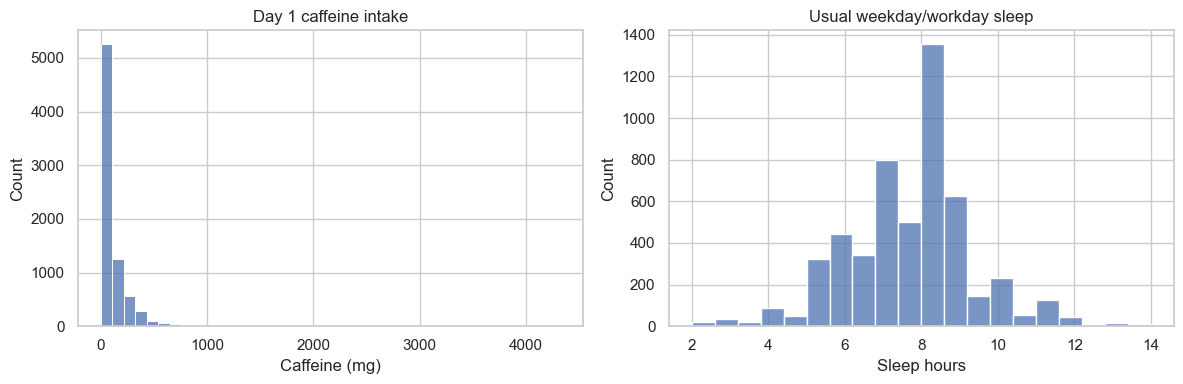

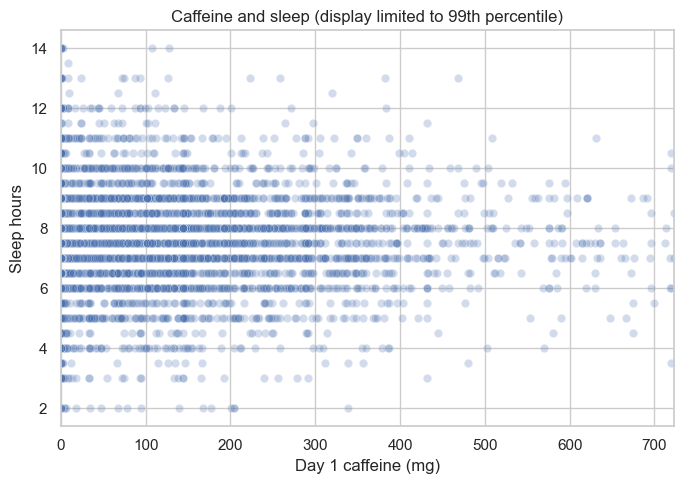

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(final_df["Caffeine_mg"].dropna(), bins = 40, ax = axes[0])
axes[0].set_title("Day 1 caffeine intake")
axes[0].set_xlabel("Caffeine (mg)")

sns.histplot(final_df["Sleep_Hours"].dropna(), bins = 20, ax = axes[1])
axes[1].set_title("Usual weekday/workday sleep")
axes[1].set_xlabel("Sleep hours")

plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(data = final_df, x="Caffeine_mg", y = "Sleep_Hours", alpha = 0.25)
plt.xlim(0, final_df["Caffeine_mg"].quantile(0.99))
plt.title("Caffeine and sleep (display limited to 99th percentile)")
plt.xlabel("Day 1 caffeine (mg)")
plt.ylabel("Sleep hours")
plt.tight_layout()
plt.show()

## 6. Compare caffeine consumption by age and sex

This section describes how Day 1 caffeine consumption differs across adult age groups and between males and females. It also shows the age-by-sex groups. These are descriptive sample comparisons, not causal conclusions.

Age groups are limited to adults (18+): 18–29, 30–39, 40–49, 50–59, and 60+.


In [9]:
# Use adults with known age, sex, and caffeine intake for these comparisons.
demo_df = final_df.loc[final_df["Age"].ge(18) & final_df["Age"].notna() & final_df["Sex"].notna() & final_df["Caffeine_mg"].notna()].copy()

demo_df["Age_Group"] = pd.cut(demo_df["Age"], bins = [18, 30, 40, 50, 60, np.inf], labels = ["18-29", "30-39", "40-49", "50-59", "60+"], right = False)

print("Adult participants included:", len(demo_df))

print("Caffeine consumption by age group:")
display(demo_df.groupby("Age_Group", observed = True)["Caffeine_mg"].agg(Participants = "count", Mean = "mean", Median = "median", SD = "std").round(2))

print("Caffeine consumption by sex:")
display(demo_df.groupby("Sex")["Caffeine_mg"].agg(Participants = "count", Mean = "mean", Median = "median", SD = "std").round(2))

print("Caffeine consumption by age group and sex:")
age_sex_caffeine = (demo_df.groupby(["Age_Group", "Sex"], observed = True)["Caffeine_mg"].agg(Participants = "count", Mean = "mean", Median = "median").round(2))
display(age_sex_caffeine)

Adult participants included: 4982
Caffeine consumption by age group:


,Participants,Mean,Median,SD
Age_Group,,,,
18-29,935,83.57,36.0,129.54
30-39,735,133.09,82.0,203.25
40-49,707,178.30,113.0,297.87
50-59,794,168.38,108.0,255.67
60+,1811,147.33,103.0,176.30


Caffeine consumption by sex:


,Participants,Mean,Median,SD
Sex,,,,
Female,2556,122.8,78.0,183.67
Male,2426,160.2,104.0,234.69


Caffeine consumption by age group and sex:


Participants    Mean  Median
Age_Group Sex                                 
18-29     Female           481   79.65    36.0
          Male             454   87.72    36.5
30-39     Female           406  106.35    69.5
          Male             329  166.09   108.0
40-49     Female           367  156.82   102.0
          Male             340  201.49   131.0
50-59     Female           419  151.65    93.0
          Male             375  187.07   135.0
60+       Female           883  126.03    96.0
          Male             928  167.59   119.5

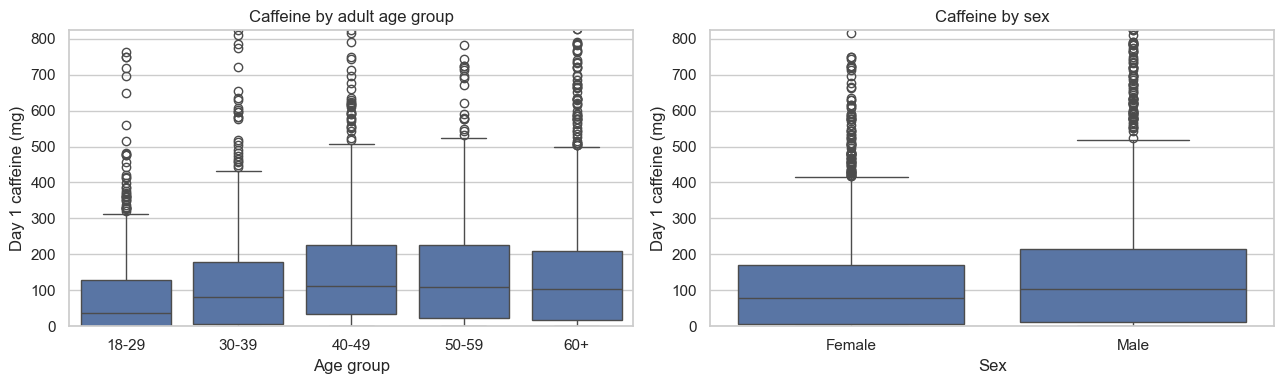

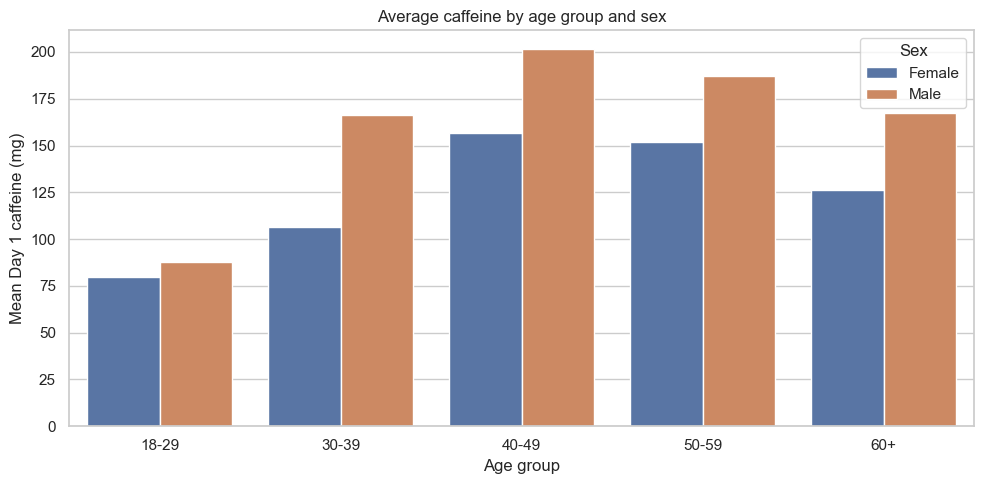

In [10]:
# Visual comparisons. The x-axis is limited to the 99th percentile for readability;
# the underlying data are not removed or changed.
caffeine_plot_max = demo_df["Caffeine_mg"].quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize = (13, 4))
sns.boxplot(data = demo_df, x = "Age_Group", y = "Caffeine_mg", ax = axes[0])
axes[0].set_ylim(0, caffeine_plot_max)
axes[0].set_title("Caffeine by adult age group")
axes[0].set_xlabel("Age group")
axes[0].set_ylabel("Day 1 caffeine (mg)")

sns.boxplot(data = demo_df, x = "Sex", y = "Caffeine_mg", ax = axes[1])
axes[1].set_ylim(0, caffeine_plot_max)
axes[1].set_title("Caffeine by sex")
axes[1].set_xlabel("Sex")
axes[1].set_ylabel("Day 1 caffeine (mg)")

plt.tight_layout()
plt.show()

plt.figure(figsize = (10, 5))
sns.barplot(data = demo_df, x = "Age_Group", y = "Caffeine_mg", hue = "Sex", errorbar = None)
plt.title("Average caffeine by age group and sex")
plt.xlabel("Age group")
plt.ylabel("Mean Day 1 caffeine (mg)")
plt.tight_layout()
plt.show()


## 7. Check caffeine's relationship with each outcome separately

Each relationship uses participants who have both caffeine and that specific outcome available. Missing information for another outcome does not remove a participant from this pairwise analysis.

Spearman correlation is used because the outcomes include skewed or ordered questionnaire responses. The results describe association, not cause and effect.


In [11]:
from scipy.stats import spearmanr

outcome_columns = {
    "Sleep hours": "Sleep_Hours",
    "Work hours": "Work_Hours",
    "Focus difficulty": "Focus_Difficulty",
    "Worry/anxiety frequency": "Worry_Frequency"}

pairwise_results = []

for outcome_name, outcome_column in outcome_columns.items():
    pair = final_df[["Caffeine_mg", outcome_column]].dropna()
    rho, p_value = spearmanr(pair["Caffeine_mg"], pair[outcome_column])

    pairwise_results.append({"Outcome": outcome_name, "Participants": len(pair), "Spearman correlation": rho, "P-value": p_value})

pairwise_results_df = pd.DataFrame(pairwise_results)
display(pairwise_results_df.round(4))


,Outcome,Participants,Spearman correlation,P-value
0,Sleep hours,5224,-0.0559,0.0001
1,Work hours,2718,0.0931,0.0000
2,Focus difficulty,4787,0.0102,0.4825
3,Worry/anxiety frequency,4912,-0.0431,0.0025


## 8. Prepare machine-learning targets and predictors

We will predict four outcomes separately:
- **Sleep hours** and **work hours** are numeric targets, so use regression.
- **Focus difficulty** (0-3) and **worry/anxiety frequency** (1-5) are ordered response categories, so use classification.

Each model excludes its own target from its predictors to prevent target leakage. The predictors include caffeine, age, sex, and the other available research variables. Missing predictor values will be imputed inside each training pipeline; rows missing the target are excluded for that particular model.

We will compare a simple baseline (predict the training-set average or most common class) with a Random Forest model. Both models use the same train/test split for each outcome.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score, f1_score, classification_report)

# Copy the modeling data and create readable numeric feature names.
ml_df = final_df.copy()
ml_df["Caffeine_mg"] = pd.to_numeric(ml_df["Caffeine_mg"], errors = "coerce")

targets = {
    "Sleep hours": ("Sleep_Hours", "regression"),
    "Work hours": ("Work_Hours", "regression"),
    "Focus difficulty": ("Focus_Difficulty", "classification"),
    "Worry/anxiety frequency": ("Worry_Frequency", "classification")}

# Predictors are selected separately for each target to avoid leakage.
feature_sets = {
    "Sleep hours": ["Caffeine_mg", "Work_Hours", "Focus_Difficulty", "Worry_Frequency", "Age", "Sex"],
    "Work hours": ["Caffeine_mg", "Sleep_Hours", "Focus_Difficulty", "Worry_Frequency", "Age", "Sex"],
    "Focus difficulty": ["Caffeine_mg", "Work_Hours", "Sleep_Hours", "Worry_Frequency", "Age", "Sex"],
    "Worry/anxiety frequency": ["Caffeine_mg", "Work_Hours", "Sleep_Hours", "Focus_Difficulty", "Age", "Sex"]}

def make_preprocessor(X):
    numeric_features = X.select_dtypes(include = np.number).columns.tolist()
    categorical_features = X.select_dtypes(exclude = np.number).columns.tolist()

    numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])

    return ColumnTransformer([("numeric", numeric_pipeline, numeric_features),("categorical", categorical_pipeline, categorical_features)])

## 9. Train and compare baseline machine-learning models

The test set is held out from training. Imputation and categorical encoding happen inside the pipeline, so they are learned from the training data only.

For regression, compare MAE, RMSE, and R-squared. For classification, compare accuracy and weighted F1-score. A model is useful only if it performs better than its simple baseline on the held-out test set.

In [13]:
results = []
trained_models = {}
test_data = {}

for outcome_name, (target, task) in targets.items():
    predictors = feature_sets[outcome_name]

    model_data = ml_df[predictors + [target]].dropna(subset=[target]).copy()
    X = model_data[predictors]
    y = model_data[target]

    # Keep the same split for the baseline and Random Forest.
    stratify_values = y if task == "classification" and y.value_counts().min() >= 2 else None

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42, stratify = stratify_values)

    preprocessor = make_preprocessor(X_train)

    if task == "regression":
        baseline = DummyRegressor(strategy = "mean")
        model = RandomForestRegressor(n_estimators = 300, min_samples_leaf = 5, random_state = 42, n_jobs = -1)

        baseline_pipe = Pipeline([("preprocess", preprocessor), ("model", baseline)])
        model_pipe = Pipeline([("preprocess", make_preprocessor(X_train)), ("model", model)])

        baseline_pipe.fit(X_train, y_train)
        model_pipe.fit(X_train, y_train)

        baseline_pred = baseline_pipe.predict(X_test)
        predictions = model_pipe.predict(X_test)

        results.extend([{
                "Outcome": outcome_name, "Model": "Mean baseline",
                "Test participants": len(y_test),
                "MAE": mean_absolute_error(y_test, baseline_pred),
                "RMSE": np.sqrt(mean_squared_error(y_test, baseline_pred)),
                "R-squared": r2_score(y_test, baseline_pred)}, {
                "Outcome": outcome_name, "Model": "Random Forest",
                "Test participants": len(y_test),
                "MAE": mean_absolute_error(y_test, predictions),
                "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
                "R-squared": r2_score(y_test, predictions)}])
    else:
        baseline = DummyClassifier(strategy="most_frequent")
        model = RandomForestClassifier(n_estimators = 300, min_samples_leaf = 5, class_weight = "balanced_subsample", random_state = 42, n_jobs = -1)

        baseline_pipe = Pipeline([("preprocess", make_preprocessor(X_train)), ("model", baseline)])
        model_pipe = Pipeline([("preprocess", make_preprocessor(X_train)), ("model", model)])

        baseline_pipe.fit(X_train, y_train)
        model_pipe.fit(X_train, y_train)

        baseline_pred = baseline_pipe.predict(X_test)
        predictions = model_pipe.predict(X_test)

        results.extend([{
                "Outcome": outcome_name, "Model": "Most-common-class baseline",
                "Test participants": len(y_test),
                "Accuracy": accuracy_score(y_test, baseline_pred),
                "Weighted F1": f1_score(y_test, baseline_pred, average = "weighted", zero_division = 0)}, {
                "Outcome": outcome_name, "Model": "Random Forest",
                "Test participants": len(y_test),
                "Accuracy": accuracy_score(y_test, predictions),
                "Weighted F1": f1_score(y_test, predictions, average = "weighted", zero_division = 0)}])

    trained_models[outcome_name] = model_pipe
    test_data[outcome_name] = (X_test, y_test, predictions)

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Outcome,Model,Test participants,MAE,RMSE,R-squared,Accuracy,Weighted F1
0,Sleep hours,Mean baseline,1045,1.2372,1.6307,-0.0005,NaN,NaN
1,Sleep hours,Random Forest,1045,1.2225,1.6195,0.0131,NaN,NaN
2,Work hours,Mean baseline,544,10.5595,14.5418,-0.0003,NaN,NaN
3,Work hours,Random Forest,544,10.0797,13.5948,0.1257,NaN,NaN
4,Focus difficulty,Most-common-class baseline,958,NaN,NaN,NaN,0.8351,0.7600
5,Focus difficulty,Random Forest,958,NaN,NaN,NaN,0.7276,0.7486
6,Worry/anxiety frequency,Most-common-class baseline,983,NaN,NaN,NaN,0.3428,0.1751
7,Worry/anxiety frequency,Random Forest,983,NaN,NaN,NaN,0.3001,0.2981


## 11. Review classification performance

Accuracy alone can hide poor performance on less common response categories. Review the classification reports to see precision, recall, and F1-score for each response category.

In [14]:
for outcome_name, (target, task) in targets.items():
    if task == "classification":
        X_test, y_test, predictions = test_data[outcome_name]
        print("\\n", outcome_name)
        print(classification_report(y_test, predictions, zero_division = 0))

\n Focus difficulty
              precision    recall  f1-score   support

         0.0       0.89      0.82      0.86       800
         1.0       0.18      0.22      0.20        99
         2.0       0.15      0.21      0.17        29
         3.0       0.19      0.40      0.26        30

    accuracy                           0.73       958
   macro avg       0.35      0.41      0.37       958
weighted avg       0.77      0.73      0.75       958

\n Worry/anxiety frequency
              precision    recall  f1-score   support

         1.0       0.37      0.44      0.40       150
         2.0       0.24      0.25      0.25       140
         3.0       0.13      0.15      0.14       121
         4.0       0.33      0.25      0.28       337
         5.0       0.35      0.40      0.37       235

    accuracy                           0.30       983
   macro avg       0.28      0.30      0.29       983
weighted avg       0.30      0.30      0.30       983



## 10. Does adding caffeine improve prediction beyond age and sex?

This comparison uses the same participants and the same train/test split for both models for each outcome:

- **Demographics-only model:** age and sex.
- **Demographics + caffeine model:** age, sex, and caffeine.

If the second model performs better on the held-out test data, caffeine adds predictive information beyond age and sex. This is a predictive comparison, not proof that caffeine causes the outcome.

The comparison is deliberately limited to age, sex, and caffeine so their combined predictive value is easy to interpret.


In [ ]:
comparison_results = []

for outcome_name, (target, task) in targets.items():
    predictors_without_caffeine = ["Age", "Sex"]
    predictors_with_caffeine = ["Age", "Sex", "Caffeine_mg"]

    # Use the same outcome-available participants and same split for both models.
    model_data = ml_df[predictors_with_caffeine + [target]].dropna(subset = [target]).copy()
    X_all = model_data[predictors_with_caffeine]
    y = model_data[target]

    stratify_values = (y if task == "classification" and y.value_counts().min() >= 2 else None)
    X_train_all, X_test_all, y_train, y_test = train_test_split(X_all, y, test_size = 0.20, random_state = 42, stratify = stratify_values)

    for model_label, predictors in [("Age + sex", predictors_without_caffeine), ("Age + sex + caffeine", predictors_with_caffeine)]:
        X_train = X_train_all[predictors]
        X_test = X_test_all[predictors]

        if task == "regression":
            estimator = RandomForestRegressor(n_estimators = 300, min_samples_leaf = 5, random_state = 42, n_jobs = -1)
        else:
            estimator = RandomForestClassifier(n_estimators = 300, min_samples_leaf = 5, class_weight = "balanced_subsample", random_state = 42, n_jobs = -1)

        pipeline = Pipeline([("preprocess", make_preprocessor(X_train)), ("model", estimator)])
        pipeline.fit(X_train, y_train)
        prediction = pipeline.predict(X_test)

        row = {"Outcome": outcome_name, "Predictors": model_label, "Test participants": len(y_test)}

        if task == "regression":
            row["MAE"] = mean_absolute_error(y_test, prediction)
            row["RMSE"] = np.sqrt(mean_squared_error(y_test, prediction))
            row["R-squared"] = r2_score(y_test, prediction)
        else:
            row["Accuracy"] = accuracy_score(y_test, prediction)
            row["Weighted F1"] = f1_score(y_test, prediction, average = "weighted", zero_division = 0)

        comparison_results.append(row)

caffeine_comparison_df = pd.DataFrame(comparison_results)
display(caffeine_comparison_df.round(4))

,Outcome,Predictors,Test participants,MAE,RMSE,R-squared,Accuracy,Weighted F1
0,Sleep hours,Age + sex,1045,1.2142,1.6138,0.0200,NaN,NaN
1,Sleep hours,Age + sex + caffeine,1045,1.2687,1.6828,-0.0656,NaN,NaN
2,Work hours,Age + sex,544,9.9054,13.4591,0.1431,NaN,NaN
3,Work hours,Age + sex + caffeine,544,10.2092,13.7062,0.1113,NaN,NaN
4,Focus difficulty,Age + sex,958,NaN,NaN,NaN,0.3330,0.4332
5,Focus difficulty,Age + sex + caffeine,958,NaN,NaN,NaN,0.6618,0.6840
6,Worry/anxiety frequency,Age + sex,983,NaN,NaN,NaN,0.2106,0.2155
7,Worry/anxiety frequency,Age + sex + caffeine,983,NaN,NaN,NaN,0.2309,0.2354


## 12. How to interpret the machine-learning results

- Compare each Random Forest model with its baseline for the **same outcome**.
- For regression, lower MAE/RMSE is better; higher R-squared is better.
- For classification, higher weighted F1 and accuracy are generally better. Check the per-class report too.
- If Random Forest does not improve over the baseline, the available variables may not predict that outcome well.
- These models do not establish that caffeine causes changes in sleep, work, focus, or worry.
- Because NHANES uses a complex survey design, these ordinary train/test models should be described as exploratory predictive models, not population-representative estimates.

**Next improvement after this baseline:** compare the same models with and without caffeine as a predictor. That directly tests whether caffeine adds predictive value beyond age, sex, and the other research variables.

- The age/sex/caffeine comparison uses identical participants and train/test splits within each outcome, so performance differences can be compared fairly.
- Pairwise caffeine/outcome correlations use the available participants for each pair rather than requiring all four outcomes to be present.
- Age-group and sex comparisons are descriptive. They do not by themselves establish statistically significant population differences.
